Import Libraries and Load Dataset

In [31]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow Version: 2.21.0
Libraries imported successfully!


In [32]:

# Load the IMDb dataset
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Dataset loaded successfully!")
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training reviews: 25000
Testing reviews: 25000
Training labels: 25000
Testing labels: 25000


In [33]:

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFirst review:")
print(X_train[0])

print("\nFirst review label:")
print(y_train[0])


Training data shape: (25000,)
Testing data shape: (25000,)

First review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345,

In [34]:

print("Negative reviews:", np.sum(y_train == 0))
print("Positive reviews:", np.sum(y_train == 1))

print("\nLabel meaning:")
print("0 = Negative")
print("1 = Positive")


Negative reviews: 12500
Positive reviews: 12500

Label meaning:
0 = Negative
1 = Positive


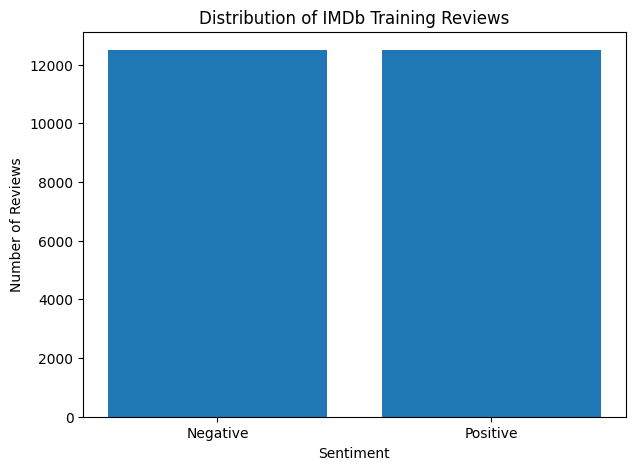

In [35]:

labels, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Negative", "Positive"],
    counts
)

plt.title("Distribution of IMDb Training Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()


Shortest review: 11
Longest review: 2494
Average review length: 238.71364


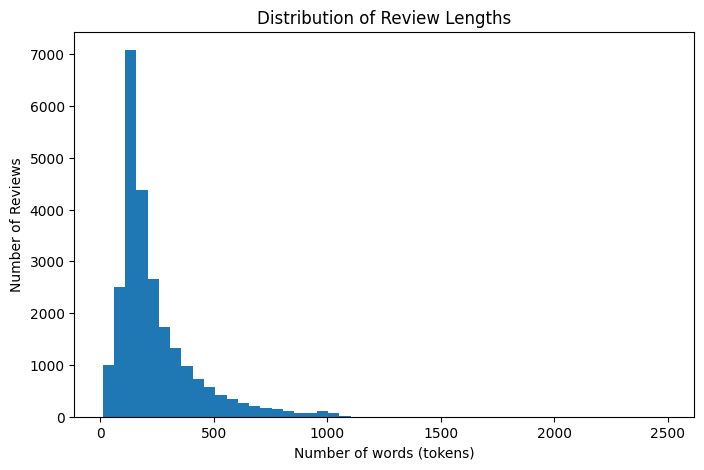

In [36]:

review_lengths = [len(review) for review in X_train]

print("Shortest review:", min(review_lengths))
print("Longest review:", max(review_lengths))
print("Average review length:", np.mean(review_lengths))

plt.figure(figsize=(8, 5))
plt.hist(review_lengths, bins=50)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of words (tokens)")
plt.ylabel("Number of Reviews")

plt.show()


In [37]:

# Get the word-to-number dictionary
word_index = imdb.get_word_index()

# Reverse the dictionary: number-to-word
reverse_word_index = {
    value: key for key, value in word_index.items()
}

# Decode the first review
decoded_review = " ".join(
    reverse_word_index.get(i - 3, "?")
    for i in X_train[0]
    if i >= 4
)

print("Decoded Review:")
print(decoded_review)

print("\nSentiment Label:", y_train[0])


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Decoded Review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and shou

In [38]:

from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 250

# Apply padding to training reviews
X_train_padded = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Apply padding to testing reviews
X_test_padded = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training data after padding:", X_train_padded.shape)
print("Testing data after padding:", X_test_padded.shape)


Training data after padding: (25000, 250)
Testing data after padding: (25000, 250)


In [39]:

print("Original review length:", len(X_train[0]))
print("Processed review length:", len(X_train_padded[0]))

print("\nFirst padded review:")
print(X_train_padded[0])

print("\nFinal training shape:", X_train_padded.shape)
print("Final testing shape:", X_test_padded.shape)


Original review length: 218
Processed review length: 250

First padded review:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480  284    5  150    4  172  112  167    2  336  385   39    4
  172 4536 1111   17  546   38   13  447    4  192   50   16    6  147
 2025   19   14   22    4 1920 4613  469    4   22   71   87   12   16
   43  530   38   76   15   13 1247    4   22   17  515   17   12   16
  626   18    2    5   62  386   12    8  316    8  106    5    4 2223
 5244   16  480   66 3785   33    4  130   12   16   38  619    5   25
  124   51   36  135   48   25 1415   33    6   22   12  215   28   77
   52    5   14  407   16   82    2    8    4  107  117 5952   15  256
    4    2    7 3766    5  723   36   71   43  530  476   26  400  317
   46    7    4    2 1029   13  104   88    4  381   15  297   98   32
 2071   56   26  141    6  194 7486   18    4  226   22   21  134  47

In [40]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dropout,
    Dense
)

print("LSTM layers imported successfully!")

LSTM layers imported successfully!


In [41]:
model = Sequential([
    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

print("LSTM model created successfully!")

LSTM model created successfully!


In [42]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [44]:
print("Optimizer:", model.optimizer)
print("Loss function:", model.loss)
print("Metrics:", model.metrics_names)

Optimizer: <keras.src.optimizers.adam.Adam object at 0x786c2c903620>
Loss function: binary_crossentropy
Metrics: ['loss', 'compile_metrics']


In [45]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

print("Early stopping configured successfully!")

Early stopping configured successfully!


In [46]:
history = model.fit(
    X_train_padded,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 92s 284ms/step - accuracy: 0.7819 - loss: 0.4589 - val_accuracy: 0.8576 - val_loss: 0.3514
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 85s 272ms/step - accuracy: 0.8907 - loss: 0.2828 - val_accuracy: 0.8672 - val_loss: 0.3709
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 91s 290ms/step - accuracy: 0.9172 - loss: 0.2228 - val_accuracy: 0.8678 - val_loss: 0.3399
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 89s 283ms/step - accuracy: 0.9391 - loss: 0.1707 - val_accuracy: 0.8566 - val_loss: 0.3689
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 145s 293ms/step - accuracy: 0.9566 - loss: 0.1228 - val_accuracy: 0.8586 - val_loss: 0.4578


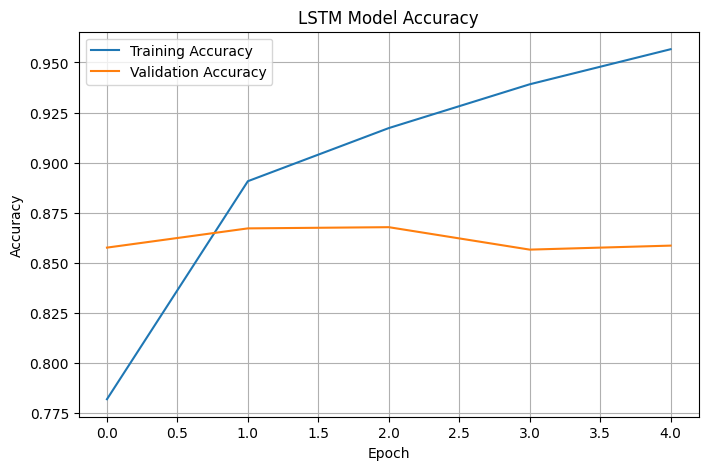

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

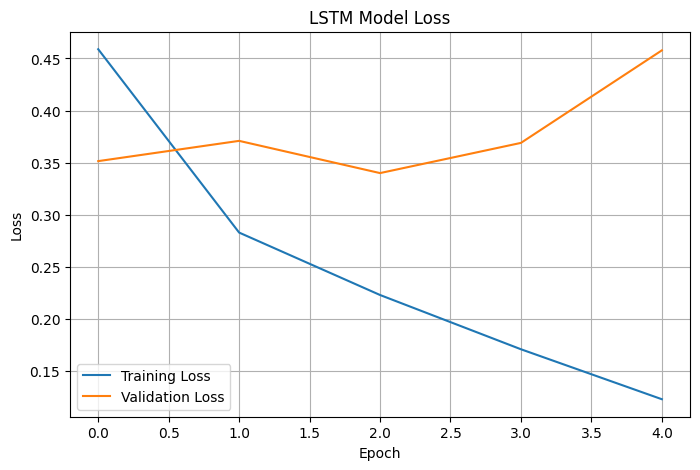

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [49]:
import os

results_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Results"

os.makedirs(results_path, exist_ok=True)

print("Results folder ready!")

Results folder ready!


In [50]:
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=1
)

print("\nTest Results")
print("----------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

782/782 ━━━━━━━━━━━━━━━━━━━━ 37s 47ms/step - accuracy: 0.8587 - loss: 0.3595

Test Results
----------------------
Test Loss: 0.35947996377944946
Test Accuracy: 0.858680009841919
Test Accuracy (%): 85.8680009841919


In [ ]:
y_pred_probability = model.predict(X_test_padded)

y_pred = (y_pred_probability >= 0.5).astype(int)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))

358/782 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))
disp.plot(cmap="Blues", values_format="d")
plt.title("LSTM Confusion Matrix")
plt.savefig(
    "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Results/confusion_matrix.png",
    bbox_inches="tight"
)
plt.show()

In [ ]:
import os

models_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Models"

os.makedirs(models_path, exist_ok=True)

print("Models folder created successfully!")

In [ ]:
model.save(models_path + "/sentiment_lstm_model.keras")

print("LSTM model saved successfully!")

In [ ]:
import json

word_index = imdb.get_word_index()

with open(models_path + "/word_index.json", "w") as file:
    json.dump(word_index, file)

print("Word dictionary saved successfully!")

In [ ]:
print("Files saved in Models folder:")

print(os.listdir(models_path))

In [ ]:
app_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Application"

os.makedirs(app_path, exist_ok=True)

print("Application folder created successfully!")

In [ ]:
%%writefile /content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Application/app.py

import streamlit as st
import tensorflow as tf
import json
import numpy as np

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import text_to_word_sequence

# Application configuration
st.set_page_config(
    page_title="Sentiment Analysis",
    page_icon="🎬",
    layout="centered"
)

# File paths
MODEL_PATH = "../Models/sentiment_lstm_model.keras"
WORD_INDEX_PATH = "../Models/word_index.json"

VOCAB_SIZE = 10000
MAX_LENGTH = 250

# Load trained model
@st.cache_resource
def load_model():
    return tf.keras.models.load_model(MODEL_PATH)

# Load word dictionary
@st.cache_data
def load_word_index():
    with open(WORD_INDEX_PATH, "r") as file:
        return json.load(file)

model = load_model()
word_index = load_word_index()

# Convert user text into numerical sequences
def preprocess_text(text):

    words = text_to_word_sequence(text)

    sequence = [1]

    for word in words:
        index = word_index.get(word, 2) + 3

        if index >= VOCAB_SIZE:
            index = 2

        sequence.append(index)

    padded_sequence = pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    return padded_sequence

# Application heading
st.title("🎬 Movie Review Sentiment Analysis")

st.write(
    "Enter a movie review below to find out "
    "whether its sentiment is positive or negative."
)

# User input
review = st.text_area(
    "Enter your movie review:",
    height=180,
    placeholder="Example: This movie was amazing..."
)

# Prediction button
if st.button("Analyze Sentiment"):

    if review.strip():

        processed_review = preprocess_text(review)

        prediction = model.predict(
            processed_review,
            verbose=0
        )[0][0]

        if prediction >= 0.5:

            st.success("Positive Sentiment 😊")
            st.write(
                f"Positive probability: {prediction * 100:.2f}%"
            )

        else:

            st.error("Negative Sentiment 😞")
            st.write(
                f"Negative probability: {(1 - prediction) * 100:.2f}%"
            )

    else:

        st.warning("Please enter a movie review first.")

st.divider()

st.caption(
    "Powered by Deep Learning and LSTM Neural Networks"
)

In [ ]:
print("TensorFlow version:", tf.__version__)

In [ ]:
%%writefile /content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Application/requirements.txt

streamlit>=1.35,<2.0
tensorflow==2.19.0
numpy<2.2

In [ ]:
print(os.listdir(app_path))

In [ ]:
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

print("Does project folder exist?", os.path.exists(project_path))

if os.path.exists(project_path):
    print("\nFolders inside your project:")
    print(os.listdir(project_path))
else:
    print("Project folder not found. Google Drive may not be mounted.")

In [ ]:
app_path = project_path + "/Application"

print("Files inside Application folder:")
print(os.listdir(app_path))

In [ ]:
models_path = project_path + "/Models"

print("Files inside Models folder:")
print(os.listdir(models_path))

In [ ]:
import shutil
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

zip_path = shutil.make_archive(
    "/content/Sentiment_Analysis_LSTM_PBL",
    "zip",
    project_path
)

print("Project ZIP created successfully!")
print(zip_path)

In [ ]:
from google.colab import files

files.download("/content/Sentiment_Analysis_LSTM_PBL.zip")

In [ ]:
notebooks_path = project_path + "/Notebooks"

os.makedirs(notebooks_path, exist_ok=True)

print("Notebooks folder created!")
print(os.listdir(project_path))

In [ ]:
for folder in ["Notebooks", "Models", "Results", "Application"]:
    folder_path = os.path.join(project_path, folder)

    print("\n" + folder + "/")

    if os.path.exists(folder_path):
        for file in os.listdir(folder_path):
            print("   ", file)

In [ ]:
import os

print(os.path.exists("/content/drive/MyDrive"))

In [ ]:
import glob

notebook_files = glob.glob(
    "/content/drive/MyDrive/**/*.ipynb",
    recursive=True
)

print("Total notebooks found:", len(notebook_files))

for file in notebook_files:
    print(file)

In [ ]:
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

notebooks_path = project_path + "/Notebooks"

os.makedirs(notebooks_path, exist_ok=True)

print("Project folder exists:", os.path.exists(project_path))
print("Notebooks folder exists:", os.path.exists(notebooks_path))
print("Files inside Notebooks:", os.listdir(notebooks_path))

In [ ]:
import os

notebooks_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL/Notebooks"

print(os.listdir(notebooks_path))

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
import os

print("My Drive contents:")

print(os.listdir("/content/drive/MyDrive"))

In [ ]:
project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

print(os.listdir(project_path))

In [ ]:
notebooks_path = project_path + "/Notebooks"

print(os.listdir(notebooks_path))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

In [ ]:
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

print("Folders and files inside project:")
print(os.listdir(project_path))

In [ ]:
import os
import shutil

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

notebooks_path = os.path.join(project_path, "Notebooks")

# Create Notebooks folder
os.makedirs(notebooks_path, exist_ok=True)

# Move the notebook into it
source = os.path.join(project_path, "01_LSTM_Sentiment_Analysis.ipynb")
destination = os.path.join(notebooks_path, "01_LSTM_Sentiment_Analysis.ipynb")

if os.path.exists(source):
    shutil.move(source, destination)
    print("Notebook moved successfully!")
else:
    print("Notebook is not in the main project folder. Checking Notebooks folder...")
    print(os.listdir(notebooks_path))

In [ ]:
print("Files inside Notebooks folder:")
print(os.listdir(notebooks_path))

In [ ]:
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

for folder in ["Notebooks", "Models", "Results", "Application"]:
    folder_path = os.path.join(project_path, folder)

    print(f"\n{folder}:")
    if os.path.exists(folder_path):
        print(os.listdir(folder_path))
    else:
        print("Folder does not exist!")

In [ ]:
import os

print(os.path.exists("/content/drive/MyDrive"))

In [ ]:
import os

path = "/content/drive/MyDrive"

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    if os.path.isdir(folder_path) and folder == "Sentiment_Analysis_LSTM_PBL":
        print("Project folder found:", folder_path)
        print("Contents:", os.listdir(folder_path))

In [ ]:
import os

path = "/content/drive/MyDrive/Colab Notebooks"

if os.path.exists(path):
    print(os.listdir(path))
else:
    print("Colab Notebooks folder not found.")

In [ ]:
import os

print("Files in /content:")

for item in os.listdir("/content"):
    print(item)

In [ ]:
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

folders = ["Notebooks", "Models", "Results", "Application"]

for folder in folders:
    folder_path = os.path.join(project_path, folder)
    os.makedirs(folder_path, exist_ok=True)
    print(folder, "created successfully")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

project_path = "/content/drive/MyDrive/Sentiment_Analysis_LSTM_PBL"

models_path = os.path.join(project_path, "Models")
results_path = os.path.join(project_path, "Results")
application_path = os.path.join(project_path, "Application")

print("Drive connected:", os.path.exists(project_path))
print("Models folder:", os.path.exists(models_path))
print("Results folder:", os.path.exists(results_path))
print("Application folder:", os.path.exists(application_path))